# Week 2 — Fitting the emergence rate in 1D

**Phase A · Classical modeling**

> Can a fitted Poisson-process rate recover the sunspot activity envelope for each hemispheric cycle?

This notebook implements the published Week 2 README deliverable. On 2026-10-13, the official `weeks/week_02/` directory contained only its README, so this is a transparent working implementation of that high-level specification, not a filled instructor template.

In [ ]:
# ── ButterflAI 2.0 standard setup — run this first ─────────────────────────
import os, sys, random, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SwRI-IDEA-Lab/butterflai2.git"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO = Path("/content/butterflai2")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(REPO / "requirements.txt")], check=True)
else:
    # Local: walk up from the notebook's folder to the repository root.
    REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "legacy" / "butterflAI_model.py").exists()), None)
    if REPO is None:
        raise RuntimeError("Could not find the butterflai2 repository root. "
                           "Open this notebook from inside your clone.")

DATA = REPO / "data"
DERIVED = DATA / "derived"
DERIVED.mkdir(exist_ok=True)
LEGACY = REPO / "legacy"
sys.path.insert(0, str(LEGACY))   # enables: from butterflAI_model import ButterflAIModel

SEED = 42
random.seed(SEED)
import numpy as np
np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available()
                          else "mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    DEVICE = "cpu"

print(f"🦋 ButterflAI 2.0 | {'Colab' if IN_COLAB else 'local'} | repo: {REPO} | device: {DEVICE}")

## Goal and modeling choices

A non-homogeneous Poisson process has a time-varying rate `λ(s)`. For events `sᵢ` observed over `[s_lo, s_hi]`, its negative log-likelihood is

`NLL = ∫[s_lo,s_hi] λ(s) ds − Σᵢ log λ(sᵢ)`.

The integral term accounts for the periods when no event occurred. Omitting it makes the likelihood unbounded: increasing the rate at every observed event would always improve the score.

We fit each of the 24 hemispheric cycles independently. We compare a constant rate with a Gaussian bell, `λ(s) = A exp(−(s−μ)²/(2σ²))`. This is a small, interpretable comparison rather than an instructor-specified model list. The shared fit window is set to `[-5, 9]` years in the 15°-crossing coordinate; it is chosen to contain the Week 1 event-time range with a margin. Because the official Week 2 notebook is not present yet, confirm this window if an instructor notebook specifies another observation interval.

**Data assumptions and limits:** each group contributes its first catalog observation as its event; first observation can lag physical emergence by several days. We apply the Week 1 selection (cycles 12–23; lifetime peak corrected area >30 MSH), use the frozen 1.0 `t₀` estimates, and treat coverage as complete as recommended for this catalog. All rate values are groups per year. This week is in-sample fitting, not held-out model comparison.

In [2]:
# Imports and reproducible settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import erf
from scipy.stats import kstest
from butterflAI_model import ButterflAIModel

SEED = 42
CYCLE_MIN, CYCLE_MAX = 12, 23
PEAK_AREA_MIN = 30.0  # MSH, strict lifetime-maximum cut
HEMISPHERES = ("north", "south")
S_LO, S_HI = -5.0, 9.0  # years since the fitted 15° crossing; common 14-year support
DURATION = S_HI - S_LO
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 9, "figure.titlesize": 13})
print(f"Cycles {CYCLE_MIN}–{CYCLE_MAX}; {2 * (CYCLE_MAX - CYCLE_MIN + 1)} independent hemicycles")
print(f"Fit window: [{S_LO}, {S_HI}] s-years ({DURATION:g} years); no cycle-length normalization")

Cycles 12–23; 24 independent hemicycles
Fit window: [-5.0, 9.0] s-years (14 years); no cycle-length normalization


## 1. Build one event per sunspot group

The daily catalog repeats groups across their lifetimes. We keep each group’s first observation for its event time and its maximum lifetime area only for the size cut. The alignment coordinate is `s = t − t₀(cycle, hemisphere)`, a shift in years, not a normalized cycle phase.

In [3]:
# Read only the columns needed; this keeps memory use modest on a laptop.
CATALOG = DATA / "composite_sunspot_groups_daily_measurements_10_23.csv"
columns = ["year", "month", "day", "hour", "minute", "second", "latitude",
           "correctedArea", "uniqueID", "CYCLE"]
daily = pd.read_csv(CATALOG, usecols=columns)
stamp = pd.to_datetime(dict(
    year=daily["year"], month=daily["month"], day=daily["day"],
    hour=daily["hour"].fillna(12).astype(int),
    minute=daily["minute"].fillna(0).astype(int),
    second=daily["second"].fillna(0).astype(int),
))
day_of_year = stamp.dt.dayofyear - 1 + stamp.dt.hour / 24 + stamp.dt.minute / 1440 + stamp.dt.second / 86400
year_length = np.where(stamp.dt.is_leap_year, 366.0, 365.0)
daily["t"] = stamp.dt.year + day_of_year / year_length
obs = daily[daily["uniqueID"].notna()].copy()
ordered = obs.sort_values("t", kind="stable")
first = ordered.drop_duplicates("uniqueID").copy()
peak_area = obs.groupby("uniqueID")["correctedArea"].max()
cycle_label = ordered.dropna(subset=["CYCLE"]).drop_duplicates("uniqueID").set_index("uniqueID")["CYCLE"]
first["peak_area"] = first["uniqueID"].map(peak_area)
first["cycle"] = first["uniqueID"].map(cycle_label)
first = first.dropna(subset=["cycle", "latitude"]).copy()
first["cycle"] = first["cycle"].astype(int)
first["hemisphere"] = np.where(first["latitude"] >= 0, "north", "south")

model_1 = ButterflAIModel()
t0 = {(c, h): model_1.lookup_t0(c, h)
      for c in range(CYCLE_MIN, CYCLE_MAX + 1) for h in HEMISPHERES}
events = first[
    first["cycle"].between(CYCLE_MIN, CYCLE_MAX)
    & (first["peak_area"] > PEAK_AREA_MIN)
].copy()
events["t0"] = [t0[(c, h)] for c, h in zip(events["cycle"], events["hemisphere"])]
events["s"] = events["t"] - events["t0"]
events["hemicycle"] = [f"{c}{h[0].upper()}" for c, h in zip(events["cycle"], events["hemisphere"])]
events = events.sort_values(["hemicycle", "s"], kind="stable").reset_index(drop=True)

print(f"Selected events: {len(events):,}; hemicycles: {events['hemicycle'].nunique()}")
print(f"Observed s range: {events['s'].min():.3f} to {events['s'].max():.3f} years")
print("Groups per hemicycle: min", int(events.groupby("hemicycle").size().min()),
      "median", int(events.groupby("hemicycle").size().median()),
      "max", int(events.groupby("hemicycle").size().max()))
assert events["hemicycle"].nunique() == 24
assert events["s"].between(S_LO, S_HI, inclusive="both").all(), "Chosen support must contain every selected event"
assert len(events) == 22_122, "Check that the Week 1 event definition and cuts match"

Selected events: 22,122; hemicycles: 24
Observed s range: -4.780 to 8.743 years
Groups per hemicycle: min 522 median 955 max 1590


## 2. Define and fit the rate models

The constant model has one parameter, `r`. Its maximum-likelihood estimate is `N / duration`. The Gaussian model has amplitude `A`, peak time `μ`, and width `σ`; we optimize `log(A)` and `log(σ)` to keep them positive. The Gaussian integral is evaluated analytically, so every objective evaluation includes the exact expected event count over the stated window.

We report training NLL per hemicycle-year for consistency with the program’s later scoreboards. Since both fits use the same events and the Gaussian has more parameters, the lower in-sample NLL alone is not evidence that it predicts better.

In [4]:
def gaussian_rate(s, theta):
    """Gaussian intensity in events/year; theta = (log_amplitude, mu, log_sigma)."""
    log_amplitude, mu, log_sigma = theta
    sigma = np.exp(log_sigma)
    return np.exp(log_amplitude - 0.5 * ((np.asarray(s) - mu) / sigma) ** 2)


def gaussian_integral(a, b, theta):
    """Exact integral of the Gaussian rate over [a, b]."""
    log_amplitude, mu, log_sigma = theta
    sigma = np.exp(log_sigma)
    z_hi = (b - mu) / (np.sqrt(2.0) * sigma)
    z_lo = (a - mu) / (np.sqrt(2.0) * sigma)
    return np.exp(log_amplitude) * sigma * np.sqrt(np.pi / 2.0) * (erf(z_hi) - erf(z_lo))


def gaussian_nll(theta, times, a=S_LO, b=S_HI):
    log_rates = theta[0] - 0.5 * ((np.asarray(times) - theta[1]) / np.exp(theta[2])) ** 2
    if not np.all(np.isfinite(log_rates)):
        return np.inf
    expected = gaussian_integral(a, b, theta)
    return float(expected - log_rates.sum())


def fit_gaussian(times, a=S_LO, b=S_HI):
    """Fit one hemicycle with multiple deterministic starts; return the best finite optimum."""
    times = np.sort(np.asarray(times, dtype=float))
    span = b - a
    mean_s = float(np.mean(times))
    median_s = float(np.median(times))
    empirical_sd = float(np.std(times))
    starts = []
    for mu0 in (mean_s, median_s, 0.0, 1.5):
        for sigma0 in (max(0.5, empirical_sd), 1.5, 3.0):
            amp0 = max(len(times) / (sigma0 * np.sqrt(2 * np.pi)), 1e-3)
            starts.append([np.log(amp0), np.clip(mu0, a, b), np.log(sigma0)])
    bounds = [(np.log(1e-6), np.log(1e6)), (a, b), (np.log(0.1), np.log(30.0))]
    results = [minimize(gaussian_nll, x0, args=(times, a, b), method="L-BFGS-B", bounds=bounds)
               for x0 in starts]
    best = min(results, key=lambda result: result.fun)
    if not np.isfinite(best.fun):
        raise RuntimeError("Gaussian rate fit did not return a finite objective")
    return best


def constant_nll(rate, count, duration=DURATION):
    if rate <= 0:
        return np.inf
    return float(rate * duration - count * np.log(rate))


fits = {}
rows = []
for label, group in events.groupby("hemicycle", sort=True):
    times = group["s"].to_numpy()
    n = len(times)
    gaussian_fit = fit_gaussian(times)
    rate_constant = n / DURATION
    nll_constant = constant_nll(rate_constant, n)
    theta = gaussian_fit.x
    fits[label] = {"theta": theta, "times": np.sort(times), "n": n}
    rows.append({
        "hemicycle": label,
        "hemisphere": group["hemisphere"].iloc[0],
        "n_events": n,
        "constant_rate_per_year": rate_constant,
        "constant_nll_per_year": nll_constant / DURATION,
        "gaussian_peak_rate_per_year": float(np.exp(theta[0])),
        "gaussian_peak_s_year": float(theta[1]),
        "gaussian_sigma_year": float(np.exp(theta[2])),
        "gaussian_nll_per_year": float(gaussian_fit.fun / DURATION),
        "optimizer_success": bool(gaussian_fit.success),
    })
fit_summary = pd.DataFrame(rows).sort_values("hemicycle").reset_index(drop=True)
display(fit_summary.round(3))

,hemicycle,hemisphere,n_events,constant_rate_per_year,constant_nll_per_year,gaussian_peak_rate_per_year,gaussian_peak_s_year,gaussian_sigma_year,gaussian_nll_per_year,optimizer_success
0,12N,north,522,37.286,-97.637,103.762,0.654,2.012,-117.565,True
1,12S,south,667,47.643,-136.436,124.965,2.029,2.132,-158.842,True
2,13N,north,716,51.143,-150.085,125.916,1.458,2.275,-171.248,True
3,13S,south,850,60.714,-188.589,149.514,1.191,2.276,-213.882,True
4,14N,north,613,43.786,-121.694,125.898,2.338,1.943,-146.156,True
5,14S,south,640,45.714,-129.024,111.032,1.765,2.305,-147.305,True
6,15N,north,794,56.714,-172.299,153.620,1.653,2.064,-200.729,True
7,15S,south,697,49.786,-144.763,144.140,0.957,1.931,-173.066,True
8,16N,north,789,56.357,-170.858,136.054,1.122,2.324,-193.399,True
9,16S,south,675,48.214,-138.648,144.879,0.837,1.860,-167.811,True


## 3. Compare the fitted curves with observed counts

Each panel is one hemispheric cycle. Bars show counts per year in half-year bins; the curve is the fitted Gaussian intensity. These are visual checks of the rate envelope, not independent validation.

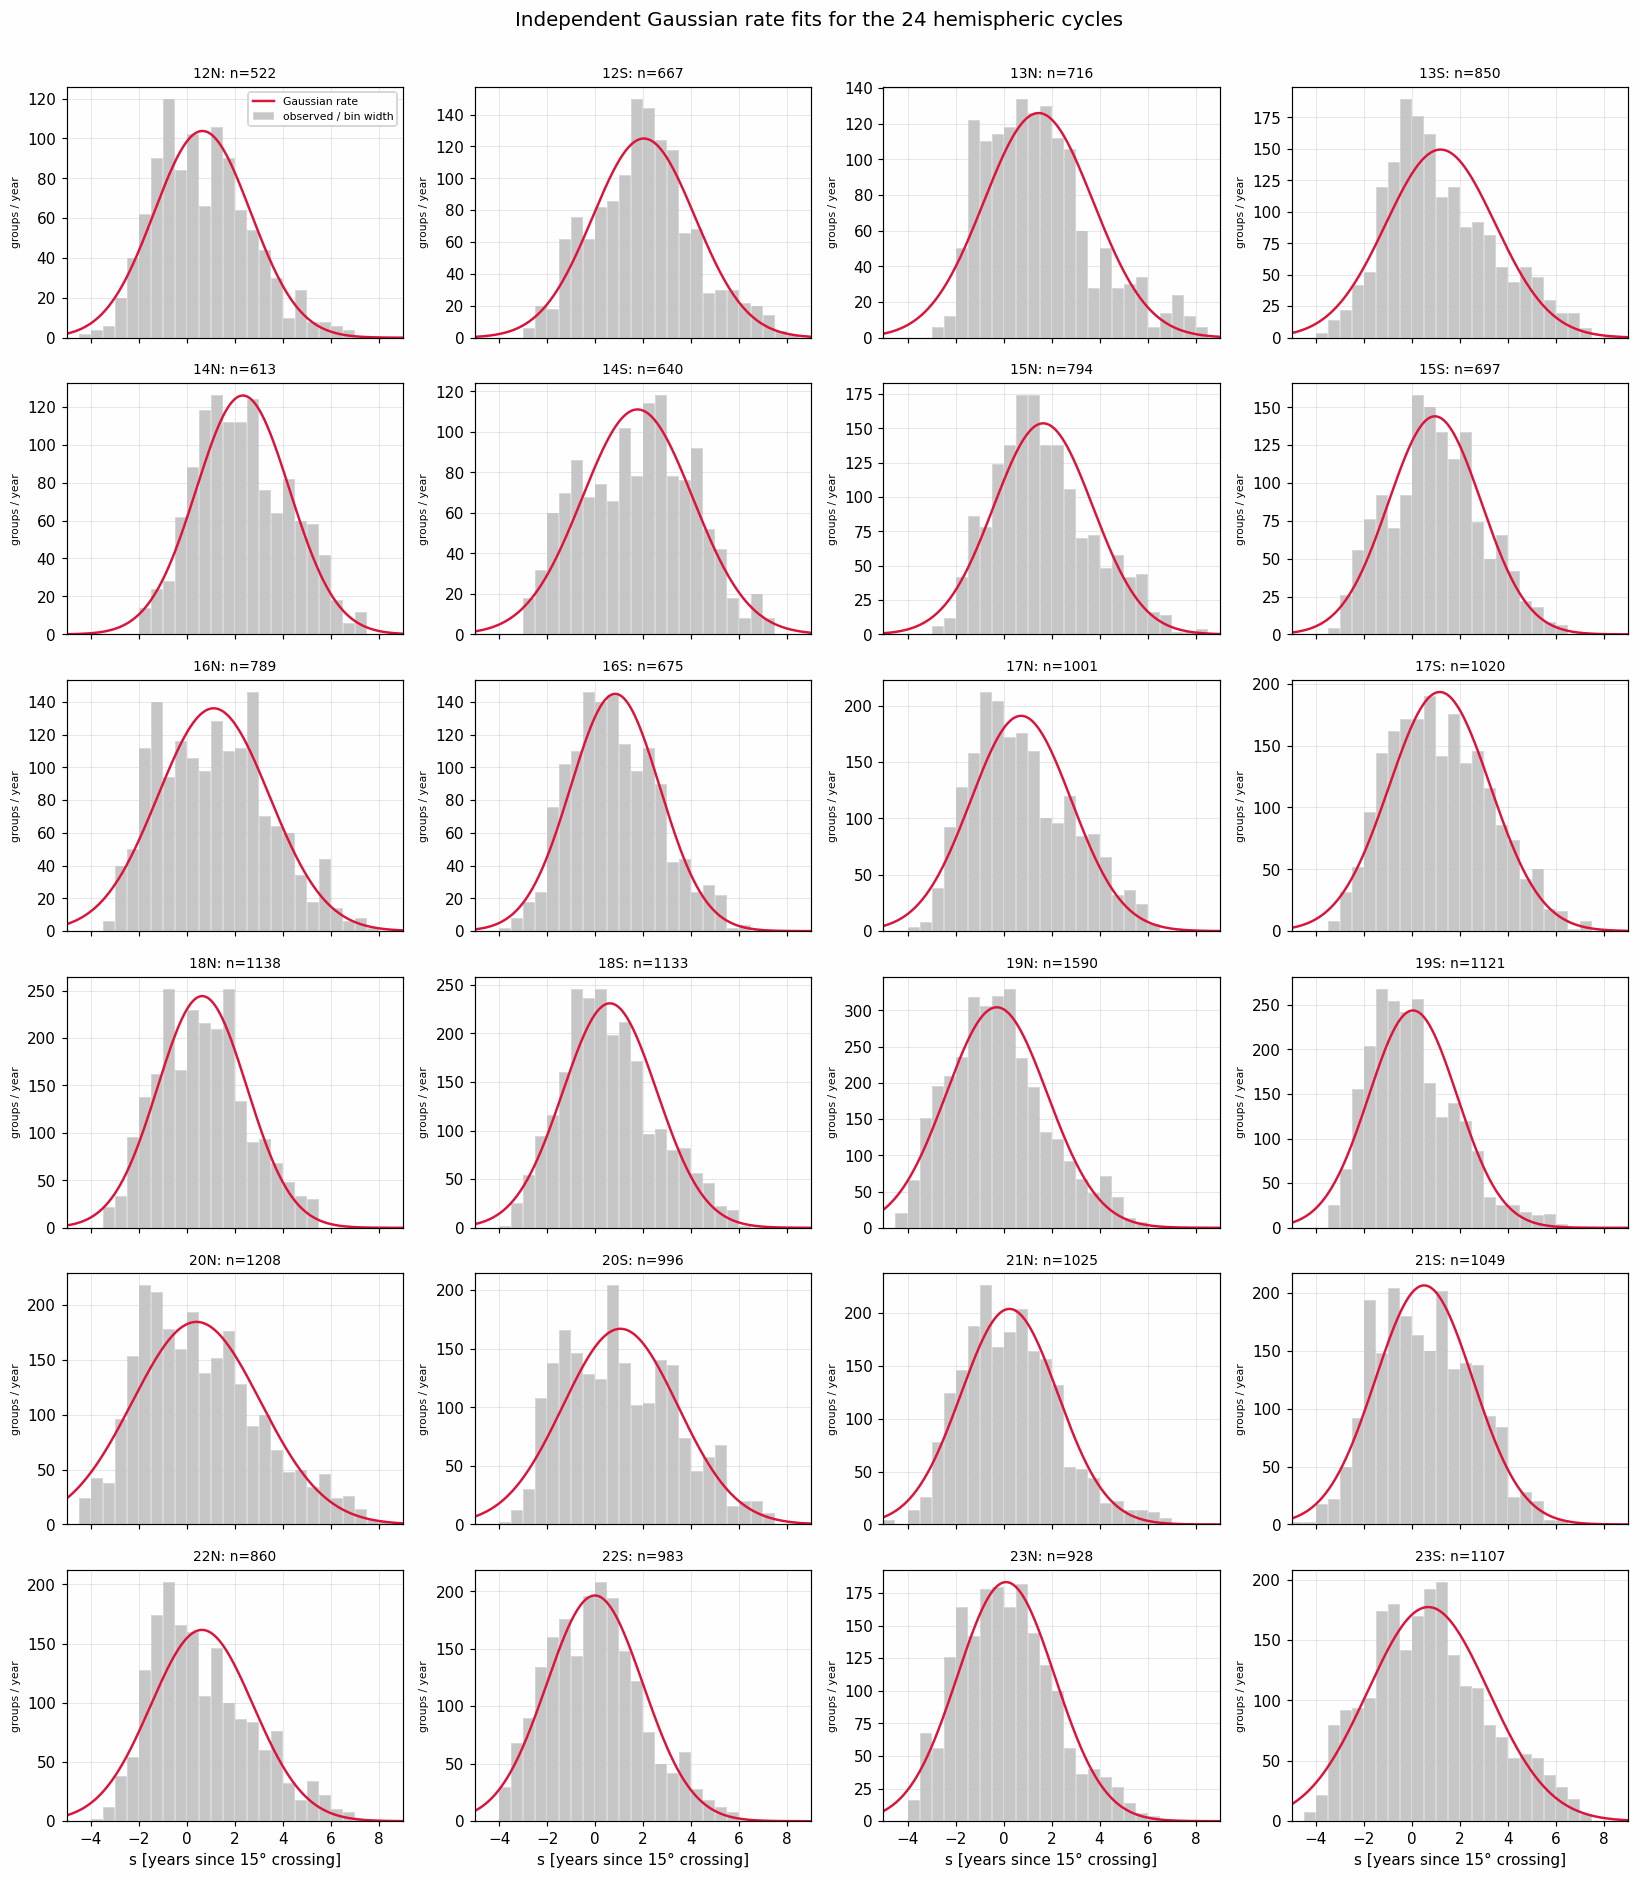

Mean in-sample NLL per hemicycle-year:
  constant: -211.971
  Gaussian: -244.462
The Gaussian has two extra parameters; this training-score comparison is descriptive only.


In [5]:
labels = fit_summary["hemicycle"].tolist()
fig, axes = plt.subplots(6, 4, figsize=(15, 17), sharex=True, sharey=False)
bin_edges = np.arange(S_LO, S_HI + 0.5, 0.5)
rate_grid = np.linspace(S_LO, S_HI, 400)
for ax, label in zip(axes.flat, labels):
    fitted = fits[label]
    counts, _ = np.histogram(fitted["times"], bins=bin_edges)
    ax.bar(bin_edges[:-1], counts / np.diff(bin_edges), width=np.diff(bin_edges), align="edge",
           color="0.78", edgecolor="white", linewidth=0.3, label="observed / bin width")
    ax.plot(rate_grid, gaussian_rate(rate_grid, fitted["theta"]), color="crimson", lw=1.6,
            label="Gaussian rate")
    ax.set_title(f"{label}: n={fitted['n']}")
    ax.set_xlim(S_LO, S_HI)
    ax.set_ylabel("groups / year", fontsize=7)
for ax in axes[-1, :]:
    ax.set_xlabel("s [years since 15° crossing]")
axes.flat[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Independent Gaussian rate fits for the 24 hemispheric cycles", y=1.002)
fig.tight_layout()
plt.show()

print("Mean in-sample NLL per hemicycle-year:")
print(f"  constant: {fit_summary['constant_nll_per_year'].mean():.3f}")
print(f"  Gaussian: {fit_summary['gaussian_nll_per_year'].mean():.3f}")
print("The Gaussian has two extra parameters; this training-score comparison is descriptive only.")

## 4. Validate parameter recovery with thinning simulations

For a known Gaussian rate, thinning starts with a homogeneous Poisson process at the peak rate and independently retains each candidate event with probability `λ(s) / λ_max`. We repeat this and refit each simulated event list. Parameter recovery should center around the known amplitude, peak time, and width, allowing for finite-sample variation.

Then we deliberately break the objective by dropping the integral term. For a Gaussian with fixed shape, the remaining negative log-likelihood decreases by `N log(k)` when amplitude is multiplied by `k`; it has no finite optimum. This demonstrates why the no-event periods must be part of the likelihood.

In [6]:
def simulate_by_thinning(theta, a=S_LO, b=S_HI, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    peak_rate = float(np.exp(theta[0]))
    n_candidates = rng.poisson(peak_rate * (b - a))
    candidates = rng.uniform(a, b, size=n_candidates)
    keep_probability = gaussian_rate(candidates, theta) / peak_rate
    return np.sort(candidates[rng.random(n_candidates) < keep_probability])


known = np.array([np.log(250.0), 1.25, np.log(2.4)])
rng = np.random.default_rng(SEED + 20)
recovered = []
for replicate in range(60):
    simulated = simulate_by_thinning(known, rng=rng)
    estimated = fit_gaussian(simulated).x
    recovered.append([np.exp(estimated[0]), estimated[1], np.exp(estimated[2]), len(simulated)])
recovered = np.asarray(recovered)
recovery = pd.DataFrame({
    "parameter": ["peak rate A [groups/year]", "peak time μ [s-years]", "width σ [years]", "event count"],
    "known": [np.exp(known[0]), known[1], np.exp(known[2]), np.nan],
    "median recovered": np.median(recovered, axis=0),
    "5th percentile": np.quantile(recovered, 0.05, axis=0),
    "95th percentile": np.quantile(recovered, 0.95, axis=0),
})
display(recovery.round(3))

# Anti-example: omit the integral. With the fitted shape held fixed, increasing amplitude
# keeps improving the broken objective, so an MLE cannot exist.
example_label = fit_summary.loc[fit_summary["n_events"].idxmax(), "hemicycle"]
example_times = fits[example_label]["times"]
example_theta = fits[example_label]["theta"]
shape_log_sum = -0.5 * np.sum(((example_times - example_theta[1]) / np.exp(example_theta[2])) ** 2)
base_log_amplitude = example_theta[0]
broken_rows = []
for multiplier in (1.0, 10.0, 100.0):
    log_amplitude = base_log_amplitude + np.log(multiplier)
    broken_objective = -(len(example_times) * log_amplitude + shape_log_sum)
    broken_rows.append({"amplitude multiplier": multiplier, "broken NLL (no integral)": broken_objective})
display(pd.DataFrame(broken_rows).round(2))
print(f"Each 10× amplitude increase lowers the broken NLL by N·log(10) = {len(example_times) * np.log(10):,.1f} nats.")

,parameter,known,median recovered,5th percentile,95th percentile
0,peak rate A [groups/year],250.00,249.683,238.447,260.706
1,peak time μ [s-years],1.25,1.238,1.156,1.342
2,width σ [years],2.40,2.403,2.322,2.468
3,event count,NaN,1495.000,1432.650,1550.050


,amplitude multiplier,broken NLL (no integral)
0,1.0,-8356.31
1,10.0,-12017.42
2,100.0,-15678.53


Each 10× amplitude increase lowers the broken NLL by N·log(10) = 3,661.1 nats.


## 5. Time-rescaling diagnostic

For a fitted rate, map each event time to cumulative intensity `Λ(s) = ∫[s_lo,s] λ(u) du`. Successive transformed event times should have unit-rate Poisson gaps, which are `Exp(1)`. The first gap from the left boundary is included; the final interval to the right boundary is right-censored and excluded.

The 24 QQ panels show the model’s in-sample gaps against theoretical exponential quantiles. The displayed KS distances are descriptive: because each rate was estimated on these same events, ordinary reference p-values would not be calibrated. Daily catalog timestamps also create ties and zero gaps, and first-observation timing is uncertain by days, so short-gap departures need caution.

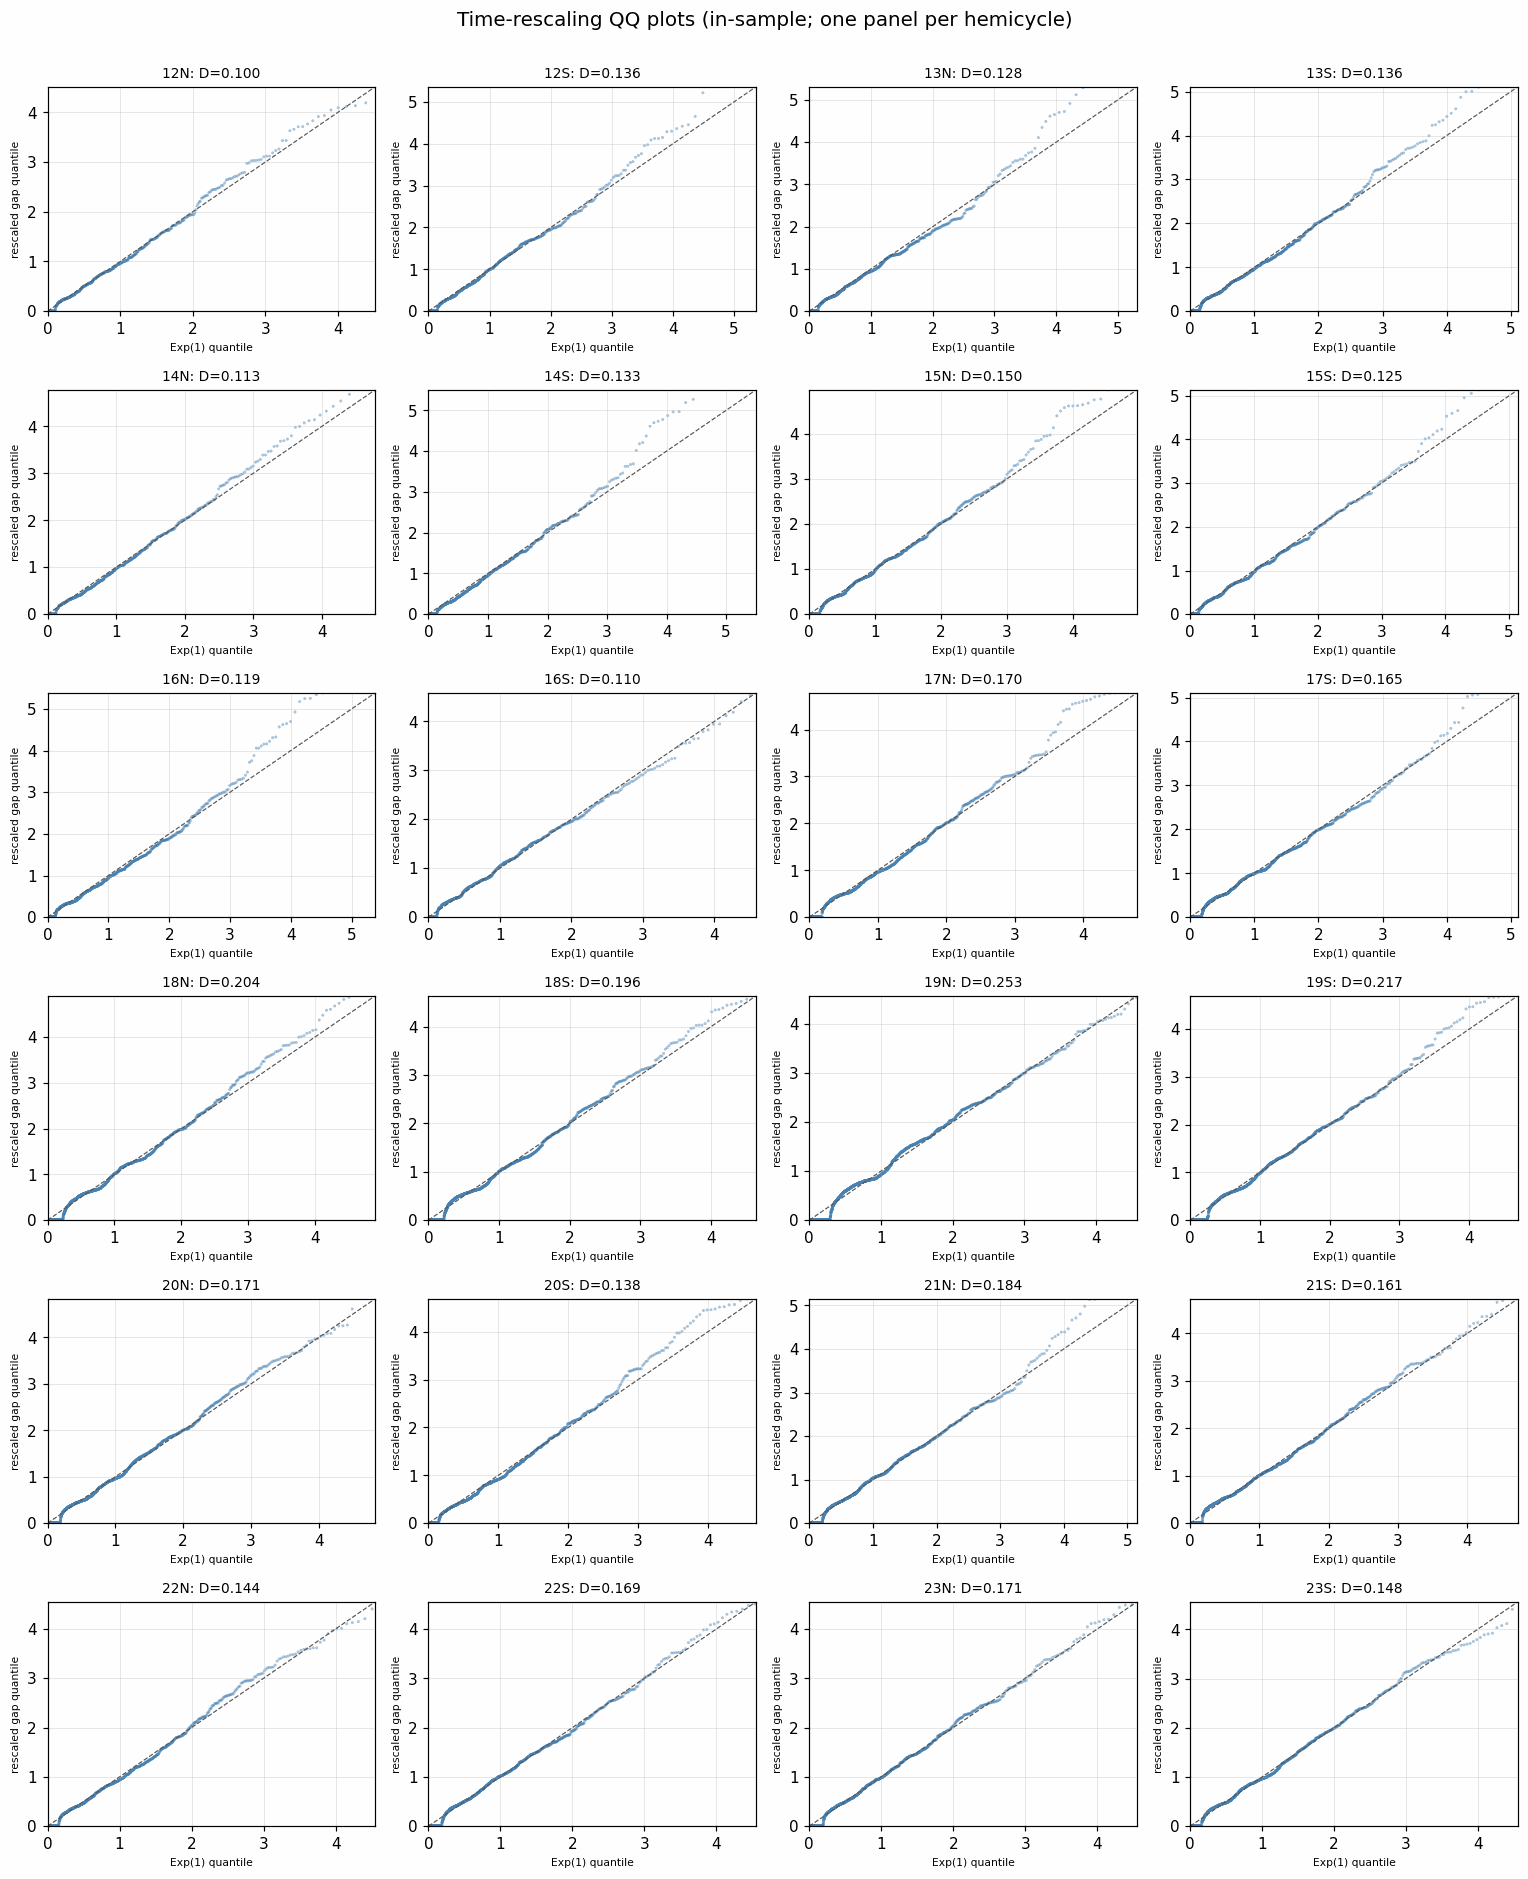

,hemicycle,n_rescaled_gaps,KS_distance_to_Exp1,fraction_zero_gaps
0,12N,522,0.0996,0.0996
1,12S,667,0.1364,0.1364
2,13N,716,0.1285,0.1285
3,13S,850,0.1365,0.1365
4,14N,613,0.1126,0.1126
5,14S,640,0.1328,0.1328
6,15N,794,0.1499,0.1499
7,15S,697,0.1248,0.1248
8,16N,789,0.1191,0.1191
9,16S,675,0.1096,0.1096


In [7]:
def cumulative_gaussian(s, theta, a=S_LO):
    return gaussian_integral(a, np.asarray(s, dtype=float), theta)


qq_rows = []
fig, axes = plt.subplots(6, 4, figsize=(14, 17))
for ax, label in zip(axes.flat, labels):
    fitted = fits[label]
    transformed_times = cumulative_gaussian(fitted["times"], fitted["theta"])
    gaps = np.diff(np.r_[0.0, transformed_times])  # omit the final right-censored gap
    gaps = np.maximum(gaps, 0.0)
    n = len(gaps)
    probabilities = (np.arange(1, n + 1) - 0.5) / n
    observed_q = np.sort(gaps)
    expected_q = -np.log1p(-probabilities)
    limit = max(float(np.quantile(observed_q, 0.99)), float(np.quantile(expected_q, 0.99)))
    ax.plot([0, limit], [0, limit], color="0.35", lw=0.8, ls="--")
    ax.scatter(expected_q, observed_q, s=4, alpha=0.45, color="steelblue", edgecolors="none")
    ax.set_title(f"{label}: D={kstest(gaps, 'expon').statistic:.3f}")
    ax.set_xlabel("Exp(1) quantile", fontsize=7)
    ax.set_ylabel("rescaled gap quantile", fontsize=7)
    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    qq_rows.append({"hemicycle": label, "n_rescaled_gaps": n,
                    "KS_distance_to_Exp1": float(kstest(gaps, "expon").statistic),
                    "fraction_zero_gaps": float(np.mean(gaps == 0))})
fig.suptitle("Time-rescaling QQ plots (in-sample; one panel per hemicycle)", y=1.002)
fig.tight_layout()
plt.show()
qq_summary = pd.DataFrame(qq_rows).sort_values("hemicycle").reset_index(drop=True)
display(qq_summary.round(4))

## Takeaways and limitations

- This notebook estimates one constant and one Gaussian time-rate for each of the 24 hemispheric cycles, with no pooling.
- The point-process likelihood includes both the event log-rates and the integrated expected count. The broken-objective check shows that removing the integral makes amplitude unbounded.
- Thinning simulations check whether the chosen Gaussian fitter can recover known parameters under its own assumptions.
- The QQ plots are diagnostics, not proof that sunspot emergence is memoryless. They are in-sample; this notebook does not claim held-out predictive improvement.
- The interval `[-5, 9]` years is an explicit working choice because the instructor Week 2 notebook was absent from the official repository when checked. The final course notebook may specify a different support, candidate family, or task list. If so, those directions supersede this working choice.
- First observation can lag true emergence by several days; the catalog is daily; and exposure is treated as complete using the course’s stated approximately 99% mean coverage for cycles 12–23.

No scientific result here should be described as a direct observation of the true emergence process: it is a fit to first-observation event times under the stated catalog and window assumptions.